# 02 - Model Training & Validation Orchestration

**Competition:** Solar Filament Segmentation Challenge 2026  
**Stage:** Baseline Training (U-Net with ResNet34 backbone)

> **Principle:** Kaggle notebooks import modular Python components from `filament_seg`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

from filament_seg.utils import set_seed, load_config, get_device, get_logger
from filament_seg.model import build_model
from filament_seg.losses import BCEDiceLoss
from filament_seg.evaluate import evaluate_semantic_predictions
from filament_seg.dataset import SolarFilamentDataset
from filament_seg.preprocessing import ForegroundAwareCrop, get_train_transform, get_val_transform

project_root = Path.cwd().resolve()
assert (project_root / "src" / "filament_seg" / "dataset.py").is_file(), project_root
logger = get_logger("training_notebook")
config = load_config(project_root / "configs" / "baseline.yaml")
set_seed(config["project"]["seed"])
device = get_device()
print(f"Python: {sys.executable}")
print(f"Project: {project_root}")
print(f"Device selected: {device}")
print(f"Experiment: {config['project']['experiment_name']}")

Python: C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation\.conda\python.exe
Project: C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation
Device selected: cpu
Experiment: baseline-unet-resnet34


## Dataset and image-level split

Split physical filenames once so alternative annotation sets cannot cross validation boundaries.

In [2]:
train_dir = project_root / "data" / "filament-segmentation-2026" / "MAGFiLO_1.0_Kaggle_2026" / "train"
image_dir = train_dir / "train_images"
annotation_path = train_dir / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

train_dataset = SolarFilamentDataset(image_dir, annotation_path, transform=get_train_transform(512))
val_dataset = SolarFilamentDataset(image_dir, annotation_path, transform=get_val_transform(512))
assert len(train_dataset) == len(val_dataset) == 707
assert len(train_dataset.images_by_filename) == 707
assert sum(map(len, train_dataset.images_by_filename.values())) == 1154
assert any(len(sets) > 1 for sets in train_dataset.images_by_filename.values())

indices = np.random.default_rng(config["project"]["seed"]).permutation(len(train_dataset))
train_indices = indices[:565].tolist()
val_indices = indices[565:].tolist()
train_names = {train_dataset.filenames[i] for i in train_indices}
val_names = {val_dataset.filenames[i] for i in val_indices}
assert len(train_names) == 565 and len(val_names) == 142
assert train_names.isdisjoint(val_names)
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)
print(f"Physical images: {len(train_dataset)}; train: {len(train_subset)}; validation: {len(val_subset)}")

Physical images: 707; train: 565; validation: 142


## Preprocessing and DataLoaders

In [3]:
# A synthetic foreground patch checks spatial alignment through cropping and augmentation.
probe = np.zeros((768, 768), dtype=np.uint8)
probe[330:430, 350:460] = 1
crop = ForegroundAwareCrop(patch_size=512, foreground_prob=1.0)
cropped = crop(image=probe.copy(), mask=probe.copy())
assert cropped["image"].shape == cropped["mask"].shape == (512, 512)
assert np.array_equal(cropped["image"], cropped["mask"])
assert cropped["mask"].sum() > 0
augmented = get_train_transform(512)(image=probe.copy(), mask=probe.copy())
assert augmented["image"].shape == augmented["mask"].shape == (512, 512)
assert np.array_equal(augmented["image"], augmented["mask"])
assert set(np.unique(augmented["mask"])) <= {0, 1}
validation_transform = get_val_transform(512)
first = validation_transform(image=probe.copy(), mask=probe.copy())
second = validation_transform(image=probe.copy(), mask=probe.copy())
assert np.array_equal(first["image"], second["image"])
assert np.array_equal(first["mask"], second["mask"])
print("Foreground crop, paired augmentation, binary labels, and deterministic validation: PASS")

Foreground crop, paired augmentation, binary labels, and deterministic validation: PASS


In [4]:
train_loader = DataLoader(train_subset, batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(val_subset, batch_size=4, shuffle=False, num_workers=0)
assert len(train_loader) == 142
assert len(val_loader) == 36

for name, loader in (("train", train_loader), ("validation", val_loader)):
    batch = next(iter(loader))
    assert set(batch) == {"image", "mask", "filename", "image_id"}
    assert batch["image"].shape == batch["mask"].shape == (4, 1, 512, 512)
    assert batch["image"].dtype == batch["mask"].dtype == torch.float32
    assert torch.isfinite(batch["image"]).all() and torch.isfinite(batch["mask"]).all()
    assert 0 <= batch["image"].min() and batch["image"].max() <= 1
    assert set(torch.unique(batch["mask"]).tolist()) <= {0.0, 1.0}
    assert len(batch["filename"]) == len(batch["image_id"]) == 4
    print(f"{name}: {len(loader)} batches, shape {tuple(batch['image'].shape)}, "
          f"image range [{batch['image'].min().item():.6f}, {batch['image'].max().item():.6f}], "
          f"mask values {torch.unique(batch['mask']).tolist()}")

train: 142 batches, shape (4, 1, 512, 512), image range [0.000000, 0.898039], mask values [0.0, 1.0]


validation: 36 batches, shape (4, 1, 512, 512), image range [0.286275, 0.737255], mask values [0.0, 1.0]


## Stage 3.2 — U-Net foreground baseline

The model outputs raw foreground logits. Dice and IoU below are diagnostic semantic metrics; the competition metric is instance-level Panoptic Quality.

In [5]:
torch.set_num_threads(min(4, torch.get_num_threads()))
assert config["model"]["in_channels"] == 1
assert config["model"]["classes"] == 1
assert config["model"]["encoder_weights"] is None, "Pretrained weights require an explicit cache check"
model = build_model(
    architecture="unet",
    encoder_name=config["model"]["encoder_name"],
    pretrained=False,  # No ResNet34 ImageNet weights are cached in this environment.
    in_channels=1,
    classes=1,
).to(device)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Model: U-Net / ResNet34; parameters: {parameter_count:,}; pretrained: no")

train_batch = next(iter(train_loader))
images = train_batch["image"].to(device)
masks = train_batch["mask"].to(device)
criterion = BCEDiceLoss(**config["training"]["loss"])
model.train()
model.zero_grad(set_to_none=True)
logits = model(images)
loss = criterion(logits, masks)
loss.backward()
assert logits.shape == masks.shape == (4, 1, 512, 512)
assert logits.dtype == torch.float32 and torch.isfinite(logits).all()
assert torch.isfinite(loss) and loss >= 0
assert any(parameter.grad is not None and torch.isfinite(parameter.grad).all()
           for parameter in model.parameters())
print(f"Forward/backward: PASS; logits {tuple(logits.shape)}; loss {loss.item():.6f}")
del images, masks, logits, loss, train_batch
model.zero_grad(set_to_none=True)

[2026-10-31 05:36:53] [INFO] [filament_seg.model]: Initialized Unet model with backbone resnet34 (weights: None, in_channels: 1, classes: 1)


Model: U-Net / ResNet34; parameters: 24,430,097; pretrained: no


Forward/backward: PASS; logits (4, 1, 512, 512); loss 0.989663


## Bounded fixed-patch learning check

Two distinct training images are sampled once and held fixed. No validation images, stochastic augmentation after sampling, or full training loop is used.

In [6]:
fixed_samples = []
for index in range(min(len(train_subset), 40)):
    sample = train_subset[index]
    if sample["mask"].sum() >= 500:
        fixed_samples.append(sample)
    if len(fixed_samples) == 2:
        break
assert len(fixed_samples) == 2, "Could not find two foreground-bearing training patches"
fixed_images = torch.stack([sample["image"] for sample in fixed_samples]).to(device)
fixed_masks = torch.stack([sample["mask"] for sample in fixed_samples]).to(device)
assert fixed_images.shape == fixed_masks.shape == (2, 1, 512, 512)
assert fixed_samples[0]["filename"] != fixed_samples[1]["filename"]

@torch.no_grad()
def fixed_patch_diagnostics(train_mode=True):
    model.train(train_mode)
    outputs = model(fixed_images)
    value = criterion(outputs, fixed_masks).item()
    scores = evaluate_semantic_predictions(
        [p for p in torch.sigmoid(outputs).cpu().numpy()],
        [t for t in fixed_masks.cpu().numpy()],
        threshold=0.5,
    )
    return value, scores["mean_dice"]

initial_loss, initial_dice = fixed_patch_diagnostics()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
training_losses = []
for step in range(50):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    predictions = model(fixed_images)
    step_loss = criterion(predictions, fixed_masks)
    assert torch.isfinite(step_loss)
    step_loss.backward()
    optimizer.step()
    training_losses.append(step_loss.item())
final_loss, final_dice = fixed_patch_diagnostics()
eval_loss, eval_dice = fixed_patch_diagnostics(train_mode=False)
print(f"Fixed patches: initial loss {initial_loss:.6f}, final loss {final_loss:.6f}; "
      f"initial Dice {initial_dice:.4f}, final Dice {final_dice:.4f}")
print(f"Evaluation mode after short fit: loss {eval_loss:.6f}, Dice {eval_dice:.4f}")
assert final_loss < initial_loss * 0.8, "Bounded run did not demonstrate meaningful loss reduction"
assert final_dice > initial_dice, "Foreground Dice did not improve"
print("Fixed-patch learning: PASS (50 optimizer steps)")

Fixed patches: initial loss 1.087150, final loss 0.296674; initial Dice 0.0405, final Dice 0.8879
Evaluation mode after short fit: loss 1.586914, Dice 0.0184
Fixed-patch learning: PASS (50 optimizer steps)


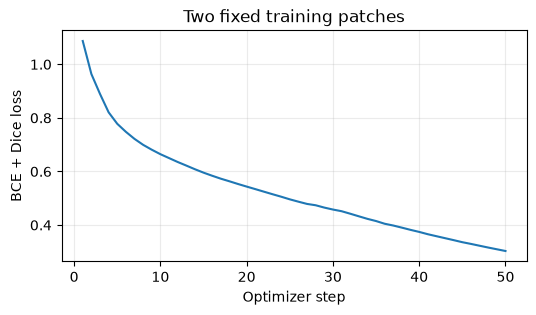

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(training_losses) + 1), training_losses)
ax.set(xlabel="Optimizer step", ylabel="BCE + Dice loss", title="Two fixed training patches")
ax.grid(alpha=0.25)
plt.show()

## Full training

Full-dataset training is intentionally deferred. The fixed-patch check above verifies that the baseline can learn.